# 01 · Veri, bölünme ve keşifsel veri analizi (EDA)
**YSA Vize Projesi – Elif Öztürk (244329059)** · Temel seed: 31085

Bu notebook: (1) `bank-additional.csv` dosyasını okur ve `duration` sütununu çıkarır, (2) %80 development / %20 test stratified bölünmeyi yapıp `dataset_split.csv` dosyasına kaydeder, (3) **yalnızca development** verisinde EDA yapar. Test verisi burada hiçbir analizde kullanılmaz.

In [ ]:
# Veri dosyası çalışma klasöründe yoksa resmi kaynaktan (UCI) indirilir.
import os, io, zipfile, urllib.request
if not os.path.exists("bank-additional.csv"):
    dis_zip = zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(
        "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip").read()))
    ic_zip = zipfile.ZipFile(io.BytesIO(dis_zip.read("bank-additional.zip")))
    open("bank-additional.csv", "wb").write(ic_zip.read("bank-additional/bank-additional.csv"))
print("bank-additional.csv hazır")

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split

# 1) Seed
SEED = 29059 + 2026   # = 31085

# 2) Veriyi oku
df = pd.read_csv("bank-additional.csv", sep=";")
print("Boyut:", df.shape)
print(df["y"].value_counts())

# 3) duration sütununu çıkar
df = df.drop(columns=["duration"])

# 4) Hedefi 0/1 yap
y = (df["y"] == "yes").astype(int)

# 5) %80 development / %20 test, stratified
dev, test = train_test_split(df, test_size=0.2, stratify=y, random_state=SEED)

print("Development:", len(dev), "| Test:", len(test))
print("Development pozitif oran:", round((dev["y"] == "yes").mean(), 4))
print("Test pozitif oran:       ", round((test["y"] == "yes").mean(), 4))

Boyut: (4119, 21)
y
no     3668
yes     451
Name: count, dtype: int64
Development: 3295 | Test: 824
Development pozitif oran: 0.1096
Test pozitif oran:        0.1092


In [ ]:
split = pd.DataFrame({
    "orig_index": list(dev.index) + list(test.index),
    "set": ["development"] * len(dev) + ["test"] * len(test),
}).sort_values("orig_index")
split.to_csv("dataset_split.csv", index=False)
print(split.head())

      orig_index          set
2223           0  development
3354           1         test
644            2  development
3476           3         test
164            4  development


## EDA (yalnızca development)
Kopya kayıtlar, sınıf dağılımı, sayısal özelliklerin istatistikleri, aykırı değerler, kategorik frekanslar ve korelasyon.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

num_cols = ["age", "campaign", "pdays", "previous", "emp.var.rate",
            "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]
cat_cols = ["job", "marital", "education", "default", "housing", "loan",
            "contact", "month", "day_of_week", "poutcome"]

# Kopya kayıtlar (ham dosyanın tamamında, bölünmeden önceki durum)
raw = pd.read_csv("bank-additional.csv", sep=";")
print("Tamamen aynı satır sayısı:", raw.duplicated().sum())
print("duration hariç aynı satır:", raw.drop(columns="duration").duplicated(keep=False).sum())

# Development özeti
ozet = pd.DataFrame({
    "tip": dev.dtypes.astype(str),
    "benzersiz": dev.nunique(),
    "unknown_sayisi": (dev == "unknown").sum(),
})
ozet

Tamamen aynı satır sayısı: 0
duration hariç aynı satır: 38


,tip,benzersiz,unknown_sayisi
age,int64,67,0
job,object,12,32
marital,object,4,10
education,object,8,140
default,object,3,632
housing,object,3,85
loan,object,3,85
contact,object,2,0
month,object,10,0
day_of_week,object,5,0


y
no     2934
yes     361
Name: count, dtype: int64
Pozitif oran: 0.1096


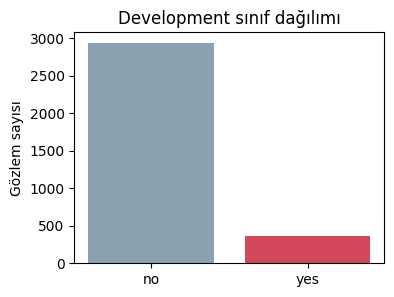

In [ ]:
sayim = dev["y"].value_counts()
print(sayim)
print("Pozitif oran:", round(sayim["yes"] / len(dev), 4))

plt.figure(figsize=(4, 3))
plt.bar(sayim.index, sayim.values, color=["#8aa1b1", "#d1495b"])
plt.title("Development sınıf dağılımı")
plt.ylabel("Gözlem sayısı")
plt.show()

                ortalama   medyan      SD     IQR      min     maks
age                40.07    38.00   10.31   15.00    18.00    88.00
campaign            2.53     2.00    2.57    2.00     1.00    29.00
pdays             959.81   999.00  193.40    0.00     0.00   999.00
previous            0.19     0.00    0.54    0.00     0.00     6.00
emp.var.rate        0.07     1.10    1.57    3.20    -3.40     1.40
cons.price.idx     93.57    93.44    0.58    0.92    92.20    94.77
cons.conf.idx     -40.50   -41.80    4.62    6.30   -50.80   -26.90
euribor3m           3.61     4.86    1.74    3.63     0.64     5.04
nr.employed      5166.09  5191.00   73.77  129.00  4963.60  5228.10

pdays = 999 oranı: 0.961


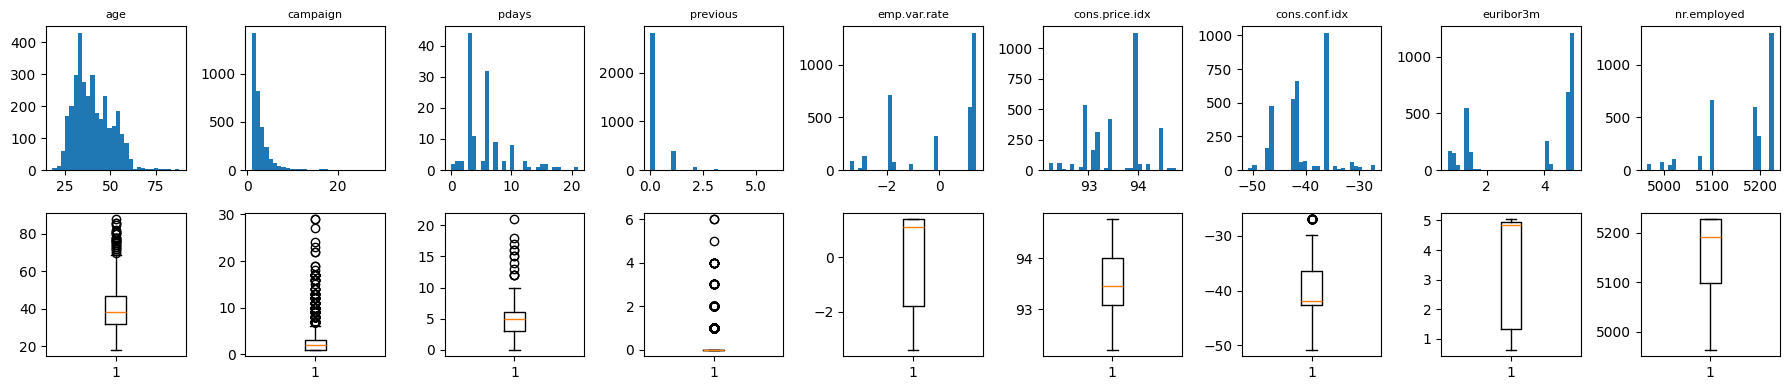

In [ ]:
def ozet_istatistik(s):
    q1, q3 = s.quantile([0.25, 0.75])
    return pd.Series({"ortalama": s.mean(), "medyan": s.median(), "SD": s.std(),
                      "IQR": q3 - q1, "min": s.min(), "maks": s.max()})

print(dev[num_cols].apply(ozet_istatistik).T.round(2))
print("\npdays = 999 oranı:", round((dev["pdays"] == 999).mean(), 3))

fig, ax = plt.subplots(2, 9, figsize=(18, 4))
for i, c in enumerate(num_cols):
    s = dev[c] if c != "pdays" else dev.loc[dev["pdays"] != 999, c]
    ax[0, i].hist(s, bins=30)
    ax[0, i].set_title(c, fontsize=8)
    ax[1, i].boxplot(s)
plt.tight_layout()
plt.show()

In [ ]:
for c in num_cols:
    s = dev[c] if c != "pdays" else dev.loc[dev["pdays"] != 999, c]
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    disari = ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).mean() * 100
    print(f"{c:15s} IQR dışı: %{disari:.1f}")

age             IQR dışı: %0.8
campaign        IQR dışı: %5.5
pdays           IQR dışı: %9.2
previous        IQR dışı: %14.8
emp.var.rate    IQR dışı: %0.0
cons.price.idx  IQR dışı: %0.0
cons.conf.idx   IQR dışı: %1.1
euribor3m       IQR dışı: %0.0
nr.employed     IQR dışı: %0.0


job
admin.           814
blue-collar      721
technician       540
services         320
management       260
retired          131
self-employed    125
entrepreneur     105
unemployed        91
housemaid         87
student           69
unknown           32
Name: count, dtype: int64 

education
university.degree      1009
high.school             740
basic.9y                468
professional.course     415
basic.4y                344
basic.6y                178
unknown                 140
illiterate                1
Name: count, dtype: int64 

default
no         2662
unknown     632
yes           1
Name: count, dtype: int64 

poutcome
nonexistent    2806
failure         373
success         116
Name: count, dtype: int64 



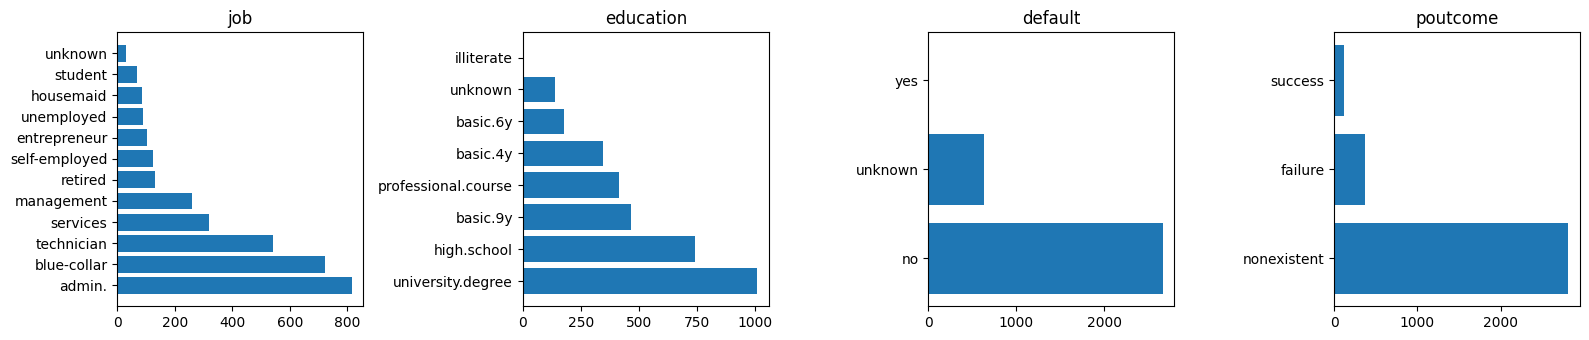

In [ ]:
for c in ["job", "education", "default", "poutcome"]:
    print(dev[c].value_counts(), "\n")

fig, ax = plt.subplots(1, 4, figsize=(16, 3.5))
for a, c in zip(ax, ["job", "education", "default", "poutcome"]):
    vc = dev[c].value_counts()
    a.barh(vc.index, vc.values)
    a.set_title(c)
plt.tight_layout()
plt.show()

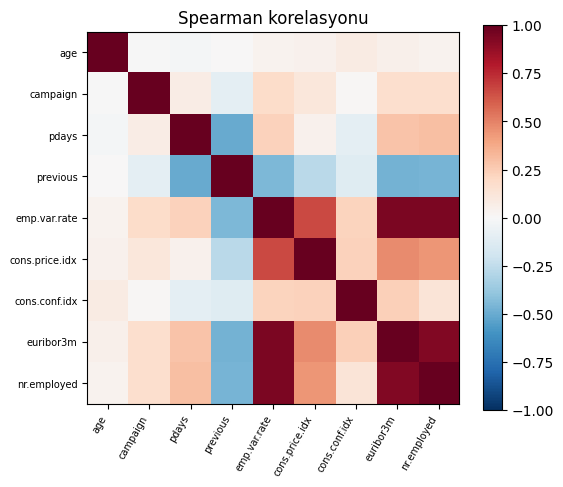

Pozitif oran | daha önce aranmamış : 0.088
Pozitif oran | daha önce aranmış   : 0.631
     euribor3m  campaign
y                       
no       4.857       2.0
yes      1.262       2.0


In [ ]:
kor = dev[num_cols].corr(method="spearman")
plt.figure(figsize=(6, 5))
plt.imshow(kor, cmap="RdBu_r", vmin=-1, vmax=1)
plt.xticks(range(len(num_cols)), num_cols, rotation=60, ha="right", fontsize=7)
plt.yticks(range(len(num_cols)), num_cols, fontsize=7)
plt.colorbar()
plt.title("Spearman korelasyonu")
plt.show()

hedef = (dev["y"] == "yes")
print("Pozitif oran | daha önce aranmamış :", round(hedef[dev["pdays"] == 999].mean(), 3))
print("Pozitif oran | daha önce aranmış   :", round(hedef[dev["pdays"] != 999].mean(), 3))
print(dev.groupby("y")[["euribor3m", "campaign"]].median())

## Ön işleme kararları ve hipotezler
* `duration` çıkarıldı (görüşme öncesi bilinmez).
* `pdays = 999` "daha önce aranmamış" kodudur: silinmez; `pdays_never` göstergesi eklenir, 999 değerleri NaN yapılıp kat-içi medyanla doldurulur.
* `unknown` ayrı kategori olarak tutulur.

**Hipotezler** (dış CV sonuçları görülmeden yazıldı):
* **H1:** campaign/previous çarpık olduğundan MinMax ölçekleme (M4), Standard ölçeklemeden (M1) daha kötü ya da en fazla eşit olacak.
* **H2:** Örnek sayısı sınırlı ve makro değişkenler birbirinin tekrarı; (64,32) mimarisi (M5) M1'e göre anlamlı kazanç sağlamayacak.
* **H3:** Aynı LR=0,001 ile SGD+Momentum (M3) daha yavaş yakınsayacak; Adam ve AdamW (M1–M2) arasında fark olmayacak.
* **H4:** Scheduler kapatıldığında (M6) etki küçük olacak.